# 05 · Network stops: strikes, cancellations, and the ripple they leave

Vehicle and pedestrian strikes stop the whole railroad for an hour or more and lead to
cancelled trains. Nothing in the pipeline records either: the feed carries no incident
field and no cancellation flag. But both leave fingerprints in the GPS record:

* **A network stop** looks like several trains frozen at the same time, held at
  stations on both sides of the incident while the line is closed.
* **A cancelled train** is a scheduled trip that never appears in the feed while the
  feed is demonstrably alive for the trains around it.

This notebook builds both detectors, checks them against the few incidents that can be
confirmed externally and against Caltrain's own monthly totals, and then measures the
ripple: how many trains, how late, for how long, and which trains get cut.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.collections import LineCollection
from common import q, connect, STATION_ORDER
from viz import BLUE, ORANGE, AQUA, VIOLET, RED, MUTED, GRID, SEQ, DIV, DIR_COLOR, SERVICE_COLOR, note

sys.path.insert(0, "..")
from src.utils.geo_utils import load_shape_points, project_to_route_many

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.max_rows", 120); pd.set_option("display.max_colwidth", 80)
con = connect()
qq = lambda s: q(s, con)

## 1. What Caltrain itself reports

The Executive Director's monthly reports (caltrain.com, "Delays and Cancellations",
p. 9) give monthly totals. Caltrain counts a train late at ≥ 6 minutes at its end-line
destination; "cancelled" includes trains terminated mid-run. Trespasser strikes
(vehicle/pedestrian) are the largest delay cause in every month they report.

In [2]:
caltrain_reported = pd.DataFrame({
    "month": ["2025-08", "2025-09", "2025-10", "2025-11", "2026-05", "2026-06", "2026-07"],
    "late_trains": [218, 84, 187, 172, 155, 204, 108],
    "avg_min_late": [27, 14, 16, 36, 15, 18, 16],
    "cancelled_trains": [10, 7, 33, 31, 7, 15, 11],
    "trespasser_delay_min": [None, None, 1258, 2882, None, 357, 1860],
}).set_index("month")
caltrain_reported

,late_trains,avg_min_late,cancelled_trains,trespasser_delay_min
month,,,,
2025-08,218,27,10,NaN
2025-09,84,14,7,NaN
2025-10,187,16,33,1258.0
2025-11,172,36,31,2882.0
2026-05,155,15,7,NaN
2026-06,204,18,15,357.0
2026-07,108,16,11,1860.0


## 2. Detector A: many trains stationary at once

A *stationary run* is a stretch of ≥ 10 consecutive pings with an identical position,
excluding trains parked at the four terminals. Positions repeat on their own about 40% of
the time (the feed clock advances without a new fix), so single stationary runs are
common; what is rare is **four or more trains stationary at the same minute**. To
separate a real stop from a feed freeze (which also freezes positions, see notebook 01),
an event must be followed by at least five trains ≥ 15 minutes late within four hours.

In [3]:
con.execute("""create or replace temp view stops_run as
with p as (select p.*, lag(lat) over w plat, lag(lon) over w plon
  from pings p join feed_days d using(date) where not d.bad_feed and hour(ts) between 4 and 23 and lat>1
  window w as (partition by trip_id, date order by ts)),
 r as (select *, case when plat is null or lat<>plat or lon<>plon then 1 else 0 end moved from p),
 g as (select *, sum(moved) over (partition by trip_id, date order by ts rows unbounded preceding) grp from r),
 runs as (select trip_id, date, grp, min(ts) t0, max(ts) t1, count(*) n, any_value(lat) lat, any_value(lon) lon from g group by 1,2,3 having count(*)>=10),
 dd as (select r.*, s.stop_name, 6371000*2*asin(sqrt(power(sin(radians(s.stop_lat-r.lat)/2),2)+cos(radians(r.lat))*cos(radians(s.stop_lat))*power(sin(radians(s.stop_lon-r.lon)/2),2))) dist from runs r, stops s),
 near as (select trip_id, date, grp, t0, t1, n, lat, lon, stop_name nearest, dist dist_station from dd qualify row_number() over (partition by trip_id, date, grp order by dist) = 1)
select * from near where not (dist_station<600 and (nearest ilike 'San Francisco%' or nearest ilike 'San Jose Diridon%' or nearest ilike 'Tamien%' or nearest ilike 'Gilroy%'))""")
con.execute("""create or replace temp view stop_min as
  select date, trip_id, t0, t1, nearest, dist_station, unnest(generate_series(date_trunc('minute',t0), date_trunc('minute',t1), interval 1 minute)) m from stops_run""")
cand = qq("""with mm as (select date, m, count(distinct trip_id) k from stop_min group by 1,2),
 ev as (select date, m, k, m - lag(m) over (partition by date order by m) gap from mm where k>=4),
 e2 as (select *, sum(case when gap is null or gap > interval 20 minute then 1 else 0 end) over (partition by date order by m) eid from ev)
select date, eid, min(m) t_start, max(m) t_end, round(epoch(max(m)-min(m))/60) hold_mins, max(k) max_trains from e2 group by 1,2 having epoch(max(m)-min(m))/60 >= 15 order by 1,3""")
con.register("cand", cand)
print(len(cand), "candidate events on", cand.date.nunique(), "days")

25 candidate events on 24 days


### Detector B: trips that never ran
A scheduled trip counts as never-ran only if the feed was alive around its departure:
≥ 20 of the 30 minutes before, and ≥ 45 of the 60 minutes after, carried pings from
other trains. That rules out collector gaps and late starts.

In [4]:
con.execute("""create or replace temp view feed_alive as select date, date_trunc('minute', ts) m, count(*) k from pings group by 1,2""")
con.execute("""create or replace temp view sched_trips as
  select date, trip_id, max(n_stops) n_stops, any_value(route_id) route_id, min(sched_ts) dep_ts, max(sched_ts) final_ts
  from (select *, CAST(date AS TIMESTAMP) + to_seconds(split_part(arrival_time,':',1)::int*3600+split_part(arrival_time,':',2)::int*60) sched_ts
        from schedule where arrival_time<'24:') group by 1,2""")
con.execute("""create or replace temp view never_ran as
  select s.*, (p.trip_id is not null) ran, d.bad_feed,
   (select count(*) from feed_alive f where f.date=s.date and f.m between s.dep_ts - interval 30 minute and s.dep_ts) alive_before,
   (select count(*) from feed_alive f where f.date=s.date and f.m between s.dep_ts and s.dep_ts + interval 60 minute) alive_after
  from sched_trips s left join (select distinct date, trip_id from pings) p using(date, trip_id) join feed_days d using(date)""")
con.execute("""create or replace temp view cancelled as
  select * from never_ran where not ran and not bad_feed and alive_before>=20 and alive_after>=45""")
qq("""select quantile_cont(n,0.5) median_per_day, quantile_cont(n,0.9) p90, max(n) mx, sum((n>=3)::int) days_with_3plus, count(*) ndays
      from (select d.date, count(c.trip_id) n from feed_days d left join cancelled c using(date) where not d.bad_feed group by 1)""")

,median_per_day,p90,mx,days_with_3plus,ndays
0,0.0,1.0,9,9.0,380


## 3. The events, with their ripple

For each candidate: trains held, trains ≥ 15 min late in the following four hours,
the worst delay, whether both directions were hit, trips cancelled from an hour before
the stop onward, and hours until the first hour with < 15% of arrivals late.

In [5]:
ev = qq("""
with m as (
 select e.date, e.t_start, e.t_end, e.hold_mins, e.max_trains,
   (select count(distinct trip_id) from clean h where h.date=e.date and h.sched_ts between e.t_start and e.t_end + interval 4 hour and h.late15) trains_15late_4h,
   (select max(delay_signed) from clean h where h.date=e.date and h.sched_ts between e.t_start and e.t_end + interval 4 hour) max_delay,
   (select count(distinct direction) from clean h where h.date=e.date and h.sched_ts between e.t_start and e.t_end + interval 3 hour and h.late15) dirs_hit,
   (select count(*) from cancelled c where c.date=e.date and c.dep_ts >= e.t_start - interval 1 hour) cancelled_after,
   (select string_agg(trip_id, ' ' order by dep_ts) from cancelled c where c.date=e.date and c.dep_ts >= e.t_start - interval 1 hour) cancelled_ids,
   (select min(hh) from (select date_trunc('hour', sched_ts) hh, avg(late4::int) l from clean h where h.date=e.date and h.sched_ts > e.t_end group by 1) x where l < 0.15) first_normal_hour,
   (select mode(nearest) from stops_run s where s.date=e.date and s.t1>=e.t_start and s.t0<=e.t_end) hold_station
 from cand e)
select date, strftime(t_start,'%H:%M') t_start, hold_mins, max_trains, hold_station, trains_15late_4h, round(max_delay) max_delay, dirs_hit,
       cancelled_after, cancelled_ids, round(epoch(first_normal_hour - t_start)/3600,1) hours_to_normal
from m order by date, t_start""")
ev["hold_station"] = ev.hold_station.str.replace(" Caltrain Station", "").str.replace(" Northbound| Southbound", "", regex=True)
ev["network_stop"] = ev.trains_15late_4h >= 5
ev[ev.network_stop].reset_index(drop=True)

,date,t_start,hold_mins,max_trains,hold_station,trains_15late_4h,max_delay,dirs_hit,cancelled_after,cancelled_ids,hours_to_normal,network_stop
0,2025-08-18,06:58,38.0,7,Palo Alto,22,70.0,2,1,510,5.0,True
1,2025-08-27,17:12,20.0,4,Redwood City,21,43.0,2,0,None,NaN,True
2,2025-10-24,16:19,38.0,6,Palo Alto,27,58.0,2,3,515 420 523,4.7,True
3,2025-11-06,15:55,131.0,8,San Antonio,36,92.0,2,0,None,NaN,True
4,2025-11-07,19:20,23.0,4,Lawrence,5,60.0,2,3,158 161 165,NaN,True
5,2025-12-19,18:37,27.0,7,San Bruno,17,72.0,2,0,None,NaN,True
6,2026-02-03,11:35,29.0,5,San Antonio,8,63.0,2,1,127,3.4,True
7,2026-02-10,18:18,69.0,10,Sunnyvale,11,107.0,2,2,429 159,4.7,True
8,2026-02-17,19:07,96.0,7,San Jose Shuttle,13,92.0,2,1,164,3.9,True
9,2026-03-19,16:30,73.0,8,Redwood City,26,66.0,2,1,424,4.5,True


Candidates that froze several trains but produced no delays are feed freezes, not
incidents (they cluster in March 2026, a month with several sub-day stale-position
bursts); they are listed here for honesty and dropped from everything below.

In [6]:
ev[~ev.network_stop][["date", "t_start", "hold_mins", "max_trains", "hold_station", "trains_15late_4h", "max_delay"]].reset_index(drop=True)

,date,t_start,hold_mins,max_trains,hold_station,trains_15late_4h,max_delay
0,2025-10-31,12:39,22.0,5,Lawrence,0,13.0
1,2026-01-13,21:48,22.0,5,Stanford,0,5.0
2,2026-02-09,18:17,28.0,6,Redwood City,0,9.0
3,2026-03-04,17:18,29.0,6,Broadway,0,8.0
4,2026-03-05,21:09,30.0,5,Lawrence,0,4.0
5,2026-03-07,18:00,39.0,6,Hayward Park,0,6.0
6,2026-03-10,15:25,44.0,7,Palo Alto,0,4.0
7,2026-03-18,16:11,39.0,7,Belmont,1,32.0
8,2026-03-24,13:04,27.0,5,Bayshore,0,11.0
9,2026-03-27,15:59,42.0,9,Hillsdale,1,26.0


### External confirmation (what could be found)
* **2025-10-24 16:19** — Caltrain Alerts posted "major delays for all trains due to a service disruption" at 16:04 PT that day.
* **2026-02-03 11:35** — a Palo Alto High School student was struck and killed near Churchill Ave around 10:15; hour-long delays and two cancelled trains were reported. Our hold cluster sits at Palo Alto; one cancellation detected.
* **2026-09-02 17:45** — a northbound train struck a vehicle near Burlingame; delays over an hour reported. Our hold cluster is Burlingame–Hillsdale–San Bruno, 4 cancellations, 3.3 h to normal.
* The others (2025-11-06 above all) could not be matched to a dated public report; Caltrain's alerts feed is not archived and news coverage of strikes is sparse. Caltrain's November 2025 report does show trespasser-strike delay minutes more than doubling in November, consistent with 11-06 being a strike.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


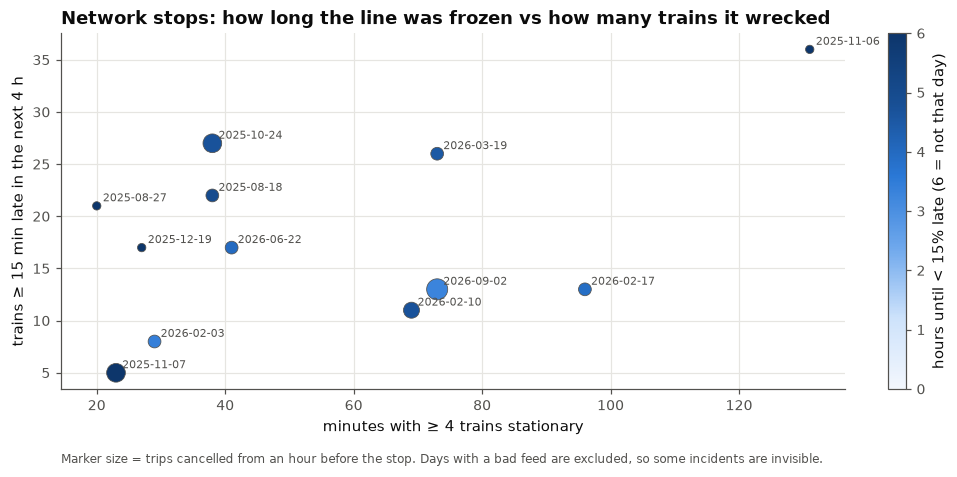

In [7]:
stops_ev = ev[ev.network_stop]
fig, ax = plt.subplots(figsize=(10, 4.2))
sc = ax.scatter(stops_ev.hold_mins, stops_ev.trains_15late_4h, s=30 + stops_ev.cancelled_after * 40, c=stops_ev.hours_to_normal.fillna(6), cmap=SEQ, vmin=0, vmax=6, edgecolor=MUTED, lw=0.5)
for _, r in stops_ev.iterrows():
    ax.annotate(f"{r.date:%Y-%m-%d}", (r.hold_mins, r.trains_15late_4h), xytext=(4, 3), textcoords="offset points", fontsize=7, color=MUTED)
plt.colorbar(sc, ax=ax, label="hours until < 15% late (6 = not that day)", fraction=0.03)
ax.set_xlabel("minutes with ≥ 4 trains stationary"); ax.set_ylabel("trains ≥ 15 min late in the next 4 h")
ax.set_title("Network stops: how long the line was frozen vs how many trains it wrecked")
note(ax, "Marker size = trips cancelled from an hour before the stop. Days with a bad feed are excluded, so some incidents are invisible.")
plt.show()

## 4. Which trains get cancelled: the expresses

On the nine days with three or more never-ran trips, 18% of scheduled Express trains
and 9% of Limiteds were dropped against 1% of Locals. Cutting the skip-stop trains is
how the railroad recovers headway after a stop; the locals keep every station served.

In [8]:
qq("""with d as (select date from cancelled group by 1 having count(*)>=3)
      select route_id, count(*) filter (where not ran) cancelled, count(*) scheduled, round(count(*) filter (where not ran)*1.0/count(*),3) rate
      from never_ran join d using(date) where not bad_feed and alive_before>=20 and alive_after>=45 group by 1 order by rate desc""")

,route_id,cancelled,scheduled,rate
0,Express,22,120,0.183
1,Limited,12,128,0.094
2,South County,3,68,0.044
3,Local Weekday,7,627,0.011


In [9]:
qq("""select date, isodow(date) dow, count(*) cancelled, string_agg(trip_id || ' (' || route_id[1:3] || ')', ', ' order by dep_ts) trips
      from cancelled group by 1 having count(*)>=3 order by 1""")

,date,dow,cancelled,trips
0,2025-10-24,5,7,"401 (Lim), 503 (Exp), 506 (Exp), 510 (Exp), 515 (Exp), 420 (Lim), 523 (Exp)"
1,2025-10-31,5,9,"515 (Exp), 518 (Exp), 420 (Lim), 523 (Exp), 425 (Lim), 526 (Exp), 429 (Lim),..."
2,2025-11-07,5,3,"158 (Loc), 161 (Loc), 165 (Loc)"
3,2025-11-18,2,6,"503 (Exp), 510 (Exp), 515 (Exp), 518 (Exp), 420 (Lim), 425 (Lim)"
4,2025-11-19,3,5,"503 (Exp), 506 (Exp), 510 (Exp), 515 (Exp), 420 (Lim)"
5,2026-02-12,4,3,"809 (Sou), 811 (Sou), 820 (Sou)"
6,2026-06-19,5,4,"519 (Exp), 429 (Lim), 428 (Lim), 159 (Loc)"
7,2026-07-15,3,3,"503 (Exp), 506 (Exp), 510 (Exp)"
8,2026-09-02,3,4,"526 (Exp), 429 (Lim), 156 (Loc), 158 (Loc)"


### Sanity check against Caltrain's monthly totals
Our never-ran count sees roughly half to two thirds of what Caltrain reports as
cancelled (theirs includes mid-run terminations and days our feed was bad). Our count of
trips ≥ 6 min late at the last *observed* stop runs higher than Caltrain's end-line
figure, because the last observed stop is the penultimate one (22nd Street for SF-bound
trains, where delay peaks) and the final stop has recovery time. Month-to-month movement
agrees: October and November 2025 are the bad months in both.

In [10]:
ours = qq("""with nr as (select strftime(date,'%Y-%m') ym, count(*) never_ran from cancelled group by 1),
 late as (select strftime(date,'%Y-%m') ym, count(*) late6_last_stop, count(distinct date) clean_days
          from (select date, trip_id, arg_max(delay_signed, stop_rank) d_last from clean group by 1,2) where d_last>=6 group by 1)
 select * from late left join nr using(ym) order by 1""").set_index("ym")
caltrain_reported.join(ours, how="outer")[["late_trains", "late6_last_stop", "cancelled_trains", "never_ran", "clean_days"]]

,late_trains,late6_last_stop,cancelled_trains,never_ran,clean_days
2025-08,218.0,194,10.0,3,21
2025-09,84.0,170,7.0,4,28
2025-10,187.0,274,33.0,21,30
2025-11,172.0,239,31.0,16,27
2025-12,NaN,218,NaN,1,30
2026-01,NaN,214,NaN,1,29
2026-02,NaN,167,NaN,9,22
2026-03,NaN,195,NaN,3,29
2026-04,NaN,181,NaN,1,27
2026-05,155.0,223,7.0,<NA>,31


## 5. Anatomy of a network stop: 2025-11-06

Every train's position along the line through the afternoon, coloured by its delay at
its most recent stop. The grey band is the window when ≥ 4 trains were stationary. The
stop is around Palo Alto / Mountain View; within minutes both directions are held from
Redwood City to Sunnyvale, and the trains that enter the segment afterwards carry 60–90
minutes of delay to the ends of the line.

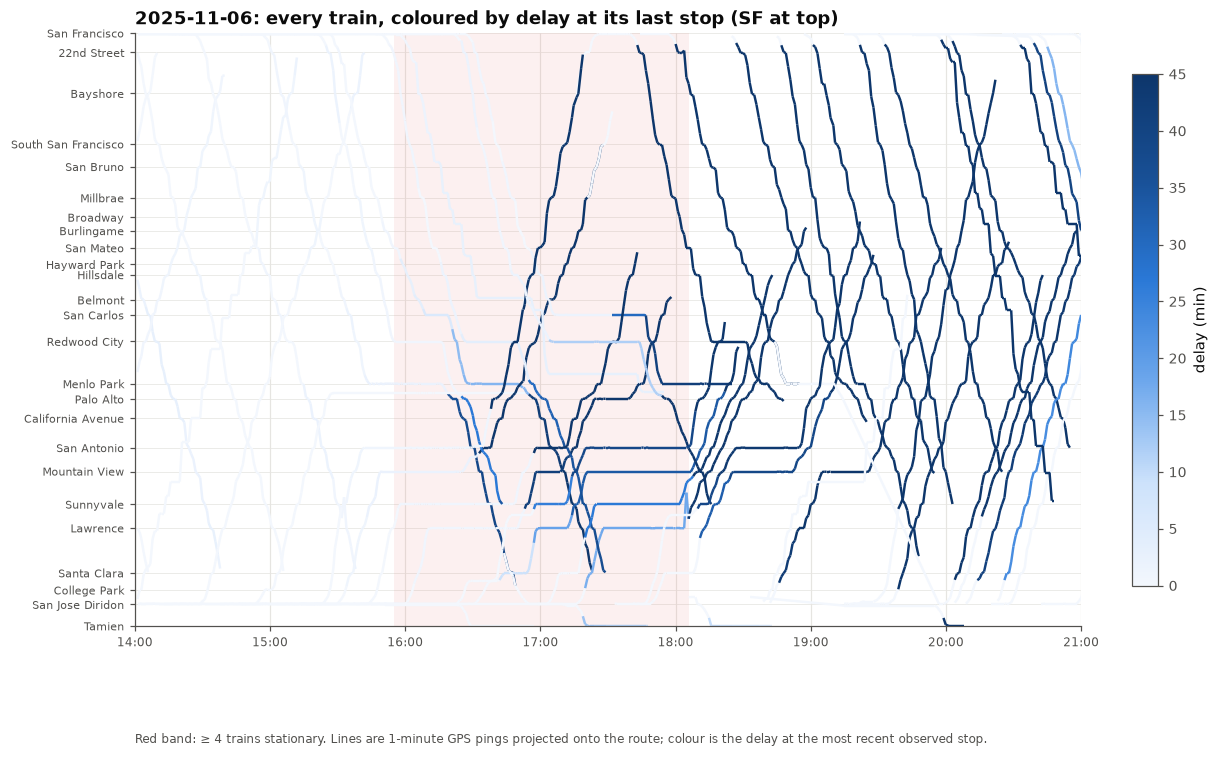

In [11]:
shape = load_shape_points("../gtfs_data")
stations = qq("select stop_name, stop_lat, stop_lon from stops where stop_id like '%1' and stop_id < '70280'")
stations["km"] = project_to_route_many(stations.stop_lat, stations.stop_lon, shape) / 1000
stations["name"] = stations.stop_name.str.replace(" Caltrain Station Northbound", "")

def marey(day: str, ax, t0="14:00", t1="21:00", title=None):
    p = qq(f"select trip_id, ts, lat, lon from pings where date='{day}' and lat>1 and ts between '{day} {t0}' and '{day} {t1}' order by trip_id, ts")
    if p.empty:
        return
    p["km"] = project_to_route_many(p.lat, p.lon, shape) / 1000
    a = qq(f"select trip_id, actual_ts ts, delay_signed from arrivals where date='{day}' and dist_m<1000 and stop_rank>1 order by ts")
    p = pd.merge_asof(p.sort_values("ts"), a.sort_values("ts"), on="ts", by="trip_id", direction="backward")
    p["delay_signed"] = p.delay_signed.fillna(0)
    norm = Normalize(0, 45)
    for tid, g in p.groupby("trip_id"):
        g = g.sort_values("ts")
        if len(g) < 3:
            continue
        pts = np.array([(t, k) for t, k in zip(g.ts.map(pd.Timestamp.timestamp), g.km)]).reshape(-1, 1, 2)
        segs = np.concatenate([pts[:-1], pts[1:]], axis=1)
        lc = LineCollection(segs, cmap=SEQ, norm=norm, linewidths=1.6)
        lc.set_array(g.delay_signed.values[1:]); ax.add_collection(lc)
    for _, e in ev[(ev.date.astype(str) == day) & ev.network_stop].iterrows():
        s = pd.Timestamp(f"{day} {e.t_start}").timestamp(); ax.axvspan(s, s + e.hold_mins * 60, color=RED, alpha=0.08, lw=0)
    xs = pd.date_range(f"{day} {t0}", f"{day} {t1}", freq="1h")
    ax.set_xlim(xs[0].timestamp(), xs[-1].timestamp()); ax.set_xticks([x.timestamp() for x in xs]); ax.set_xticklabels([x.strftime("%H:%M") for x in xs], fontsize=8)
    ax.set_ylim(0, 78); ax.set_yticks(stations.km); ax.set_yticklabels(stations.name, fontsize=7); ax.grid(True, axis="y", lw=0.5)
    ax.invert_yaxis(); ax.set_title(title or day)
    return norm

fig, ax = plt.subplots(figsize=(12, 7))
norm = marey("2025-11-06", ax, "14:00", "21:30", "2025-11-06: every train, coloured by delay at its last stop (SF at top)")
plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=SEQ), ax=ax, label="delay (min)", fraction=0.025)
note(ax, "Red band: ≥ 4 trains stationary. Lines are 1-minute GPS pings projected onto the route; colour is the delay at the most recent observed stop.")
plt.show()

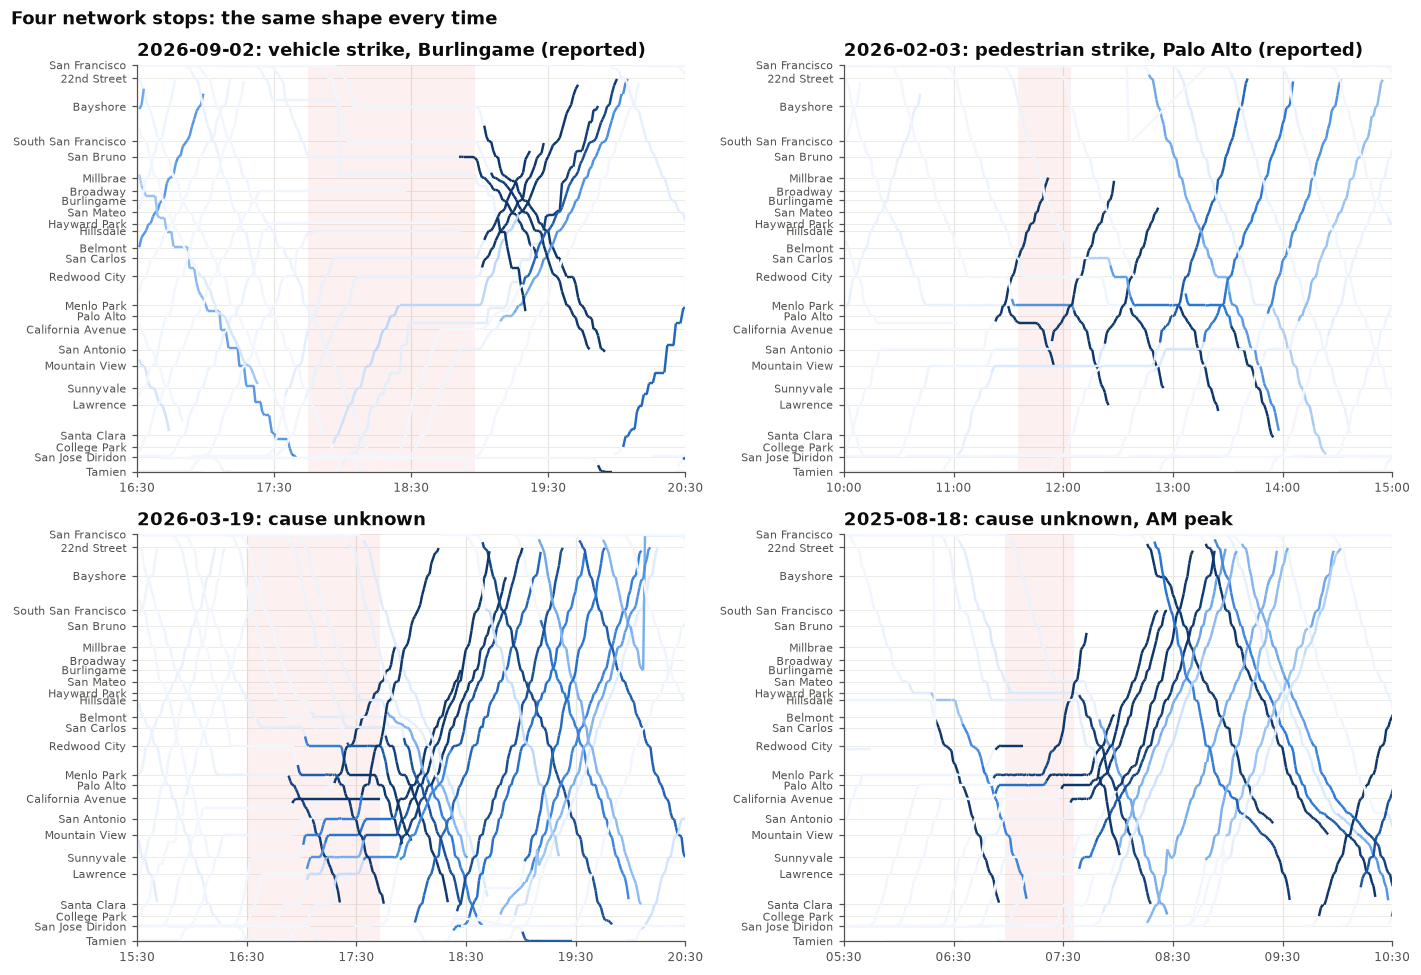

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, (day, lo, hi, cause) in zip(axes.flat, [("2026-09-02", "16:30", "21:00", "vehicle strike, Burlingame (reported)"),
                                             ("2026-02-03", "10:00", "15:00", "pedestrian strike, Palo Alto (reported)"),
                                             ("2026-03-19", "15:30", "20:30", "cause unknown"),
                                             ("2025-08-18", "05:30", "11:00", "cause unknown, AM peak")]):
    marey(day, ax, lo, hi, f"{day}: {cause}")
fig.suptitle("Four network stops: the same shape every time", x=0.01, ha="left", fontsize=12, fontweight="semibold")
plt.tight_layout(); plt.show()

## 6. How far the ripple reaches

For the confirmed network stops, each train's delay at its last observed stop against
its scheduled departure time relative to the start of the stop. Trains already en route
take the full hit; trains departing up to two hours *after* the line reopened are still
15–40 minutes late, because the equipment and crews they need are the ones stuck up the
line.

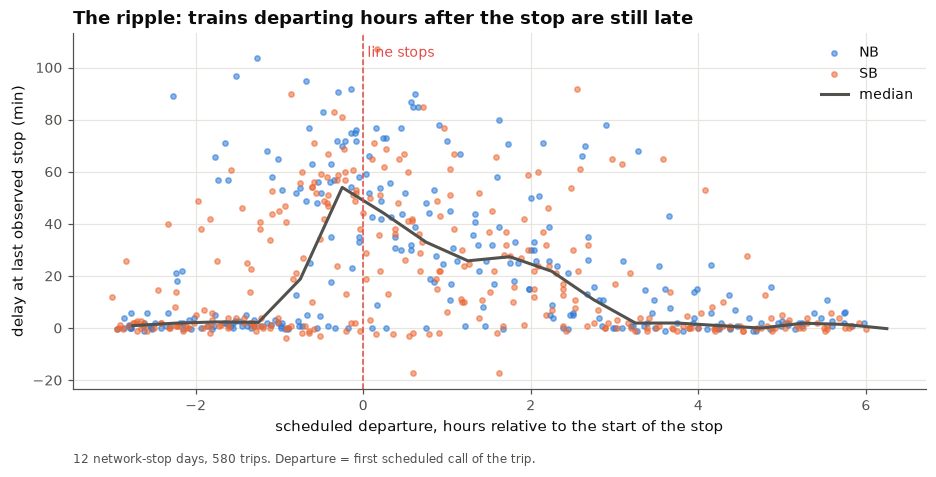

In [13]:
rip = qq("""with last as (select date, trip_id, direction, arg_max(delay_signed, stop_rank) d_last, min(sched_ts) dep from clean group by 1,2,3)
            select l.date, l.trip_id, l.direction, l.d_last, epoch(l.dep - e.t_start)/3600 rel_h, e.hold_mins
            from last l join cand e using(date) where epoch(l.dep - e.t_start)/3600 between -3 and 6""")
rip = rip.merge(ev[ev.network_stop][["date", "t_start"]].assign(date=lambda d: d.date), on="date")
fig, ax = plt.subplots(figsize=(10, 4.2))
for d, g in rip.groupby("direction"):
    ax.scatter(g.rel_h, g.d_last, s=12, color=DIR_COLOR[d], alpha=0.55, label=d)
b = rip.assign(bin=(rip.rel_h // 0.5) * 0.5).groupby("bin").d_last.median()
ax.plot(b.index + 0.25, b.values, color=MUTED, lw=2, label="median")
ax.axvline(0, color=RED, lw=1, ls="--"); ax.text(0.05, ax.get_ylim()[1] * 0.92, "line stops", color=RED, fontsize=9)
ax.set_xlabel("scheduled departure, hours relative to the start of the stop"); ax.set_ylabel("delay at last observed stop (min)")
ax.set_title("The ripple: trains departing hours after the stop are still late"); ax.legend()
note(ax, f"{rip.date.nunique()} network-stop days, {len(rip)} trips. Departure = first scheduled call of the trip.")
plt.show()

In [14]:
rip.assign(bin=pd.cut(rip.rel_h, [-3, -1, 0, 1, 2, 3, 4, 6])).groupby("bin", observed=True).d_last.agg(trips="size", median="median", p75=lambda s: s.quantile(.75), share_late15=lambda s: (s > 15).mean()).round(2)

,trips,median,p75,share_late15
bin,,,,
"(-3, -1]",143,1.88,5.87,0.20
"(-1, 0]",100,47.94,58.20,0.68
"(0, 1]",81,41.03,59.88,0.81
"(1, 2]",62,27.38,40.38,0.71
"(2, 3]",63,15.93,31.92,0.51
"(3, 4]",48,1.43,11.65,0.15
"(4, 6]",82,0.97,3.83,0.05


## 7. How much of all severe delay is this?

In [15]:
ev_ns = ev[ev.network_stop][["date", "t_start"]].assign(t_start=lambda d: pd.to_datetime(d.date.astype(str) + " " + d.t_start))
con.register("ev_ns", ev_ns)
qq("""with e as (select c.date, c.t_start, c.t_end from cand c join ev_ns n on n.date=c.date and n.t_start=c.t_start)
      select round(sum(case when e.date is not null and h.sched_ts between e.t_start - interval 30 minute and e.t_end + interval 5 hour then late15::int else 0 end)*1.0/sum(late15::int),3) share_of_15min_late_in_stop_windows,
             count(distinct e.date) stop_days, sum(late15::int) all_15min_late
      from clean h left join e on e.date=h.date""")

,share_of_15min_late_in_stop_windows,stop_days,all_15min_late
0,0.308,12,5499.0


## 8. Toward an animation (next phase)

Everything the time-distance diagrams use is already in the table: one position per
train per minute, a route projection, and the delay at the last observed stop. An
animation is the same data played frame by frame (one frame per minute, trains as dots on
the line map or on the route axis, colour = delay, the stop window highlighted). The
detector above gives the list of days worth animating and the minute to start from.
What it cannot show is *why* the line stopped; that needs 511's ServiceAlerts feed, which
is not collected.